# Can a model predict whether SPY goes up tomorrow?

**The question:** using only information available at today's close, can a model predict whether the S&P 500 (through the SPY fund) closes higher tomorrow, better than simple rules can?

**Why direction, not price:** tomorrow's price is almost always close to today's, so a "predicted vs. actual price" chart looks impressive even for a model that has learned nothing. Up-or-down is a much harder test to fake.

**What "honest" means in this notebook:**
1. **No peeking at the future.** Every feature uses only data up to today's close, and the model is always tested on years it never saw during training.
2. **Real baselines.** Beating a coin flip is easy because markets rise slightly more often than they fall. The bar is the rule "always predict up."
3. **Noise check.** Every accuracy comes with a range showing how much could be luck.
4. **Money check.** A backtest with trading costs, compared against simply buying and holding.
5. **Pipeline checks.** The same code must find nothing in pure noise, and must find a pattern that is planted on purpose.

In [1]:
import sys
from pathlib import Path

# Let the notebook import the code in ../src
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data import load_prices, make_random_walk, make_planted_pattern
from src.features import FEATURES, ALL_FEATURES, build_dataset
from src.evaluate import (get_models, first_test_year, walk_forward, baseline_predictions,
                          accuracy_table, accuracy_by_year, backtest_table)

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (11, 4)

# Settings: change these to experiment
TICKER = "SPY"
START = "2005-01-01"
FIRST_TEST_YEAR = None   # None = automatic: the first year with about 4 years of history before it
COST = 0.001             # 0.1% cost per buy or sell in the backtest

## 1. Data

Daily prices, adjusted for dividends and splits. The first run downloads them; later runs load the saved copy in `data/`. Use `load_prices(..., refresh=True)` to pull the latest days.

If the data was downloaded while the US market was still open, today's row is left out automatically: its "close" isn't final yet.

5,476 trading days, 2005-01-03 to 2026-10-08


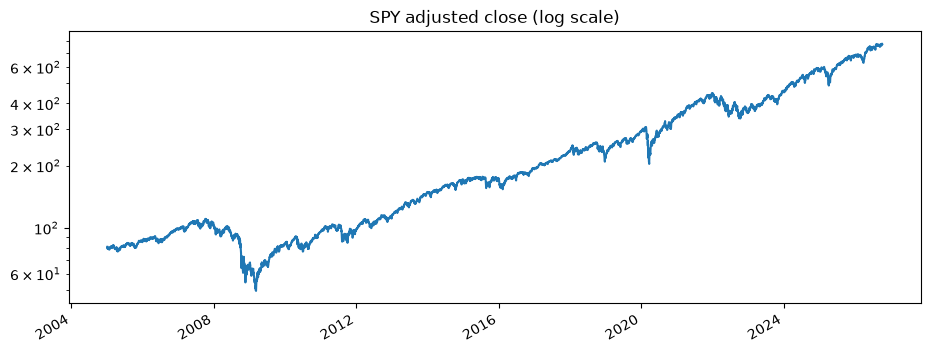

In [2]:
prices = load_prices(TICKER, START)
print(f"{len(prices):,} trading days, {prices.index[0].date()} to {prices.index[-1].date()}")

ax = prices["Close"].plot(logy=True, title=f"{TICKER} adjusted close (log scale)")
ax.set_xlabel("")
plt.show()

In [3]:
daily_ret = prices["Close"].pct_change().dropna()
print(f"Share of up days: {(daily_ret > 0).mean():.1%}")

Share of up days: 55.0%


That share is the accuracy of "always predict up." Any model has to beat it, not 50%, to show it has learned something.

## 2. Features and label

Eight features are calculated. The models use five of them, one per idea:

| Feature | Meaning | Used by the models? |
|---|---|---|
| `ret_1d` | Return over the last day | Yes |
| `ret_5d` | Return over the last 5 days (one week) | Yes |
| `dist_ma50` | How far today's price is above or below its 50-day average (longer trend) | Yes |
| `vol_20d` | How jumpy daily returns were over the last 20 days (risk) | Yes |
| `volume_ratio` | Today's volume compared with its 20-day average (activity) | Yes |
| `ret_10d`, `ret_20d` | Return over the last 10 and 20 days | No: overlap with the kept features |
| `dist_ma10` | Distance from the 10-day average | No: nearly a copy of `ret_5d` |

The **label** (`target`) is 1 if tomorrow's close is higher than today's, else 0. `next_ret` is tomorrow's return, kept for the backtest.

In [4]:
data = build_dataset(prices)
if FIRST_TEST_YEAR is None:
    FIRST_TEST_YEAR = first_test_year(data)
print(f"First test year: {FIRST_TEST_YEAR}")
data.head()

First test year: 2010


,ret_1d,ret_5d,ret_10d,ret_20d,dist_ma10,dist_ma50,vol_20d,volume_ratio,next_ret,target
Date,,,,,,,,,,
2005-03-15,-0.0083,-0.0179,-0.0090,-0.0045,-0.0105,0.0048,0.0073,0.0720,-0.0085,0
2005-03-16,-0.0085,-0.0153,-0.0169,-0.0166,-0.0172,-0.0035,0.0075,0.2521,0.0020,1
2005-03-17,0.0020,-0.0155,-0.0153,-0.0153,-0.0137,-0.0016,0.0075,0.0404,-0.0030,0
2005-03-18,-0.0030,-0.0115,-0.0303,-0.0102,-0.0136,-0.0047,0.0073,-0.0004,-0.0037,0
2005-03-21,-0.0037,-0.0213,-0.0344,-0.0152,-0.0138,-0.0084,0.0073,0.0051,-0.0102,0


### Why only five? Overlapping features

When two features measure nearly the same thing, a model can split weight between them or give them opposite weights that cancel out, so you can no longer read what it learned. Correlation runs from -1 to 1; values near ±1 mean two features move together.

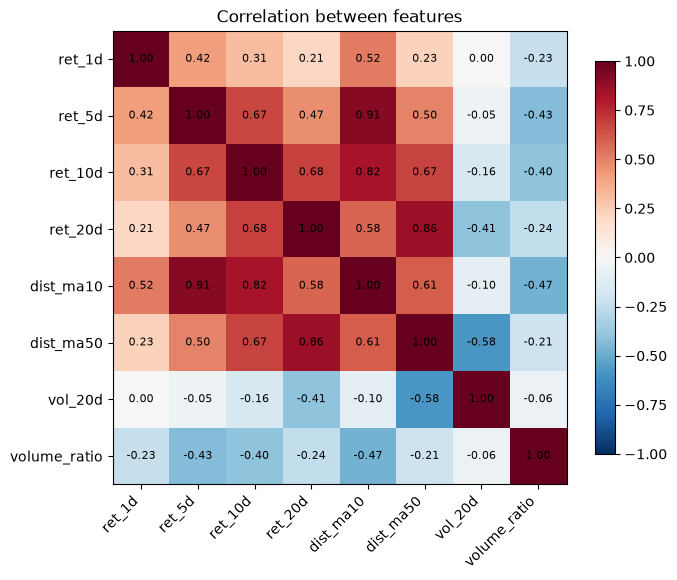

In [5]:
corr = data[ALL_FEATURES].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ALL_FEATURES)), ALL_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(ALL_FEATURES)), ALL_FEATURES)
for i in range(len(ALL_FEATURES)):
    for j in range(len(ALL_FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation between features")
plt.tight_layout()
plt.show()

How strongly does each feature relate to tomorrow's return? Expect numbers very close to zero, which is the first hint of how hard this is.

In [6]:
data[ALL_FEATURES].corrwith(data["next_ret"]).sort_values().to_frame("correlation with next-day return")

,correlation with next-day return
ret_1d,-0.1036
dist_ma10,-0.0859
ret_5d,-0.0767
dist_ma50,-0.0527
ret_10d,-0.0508
ret_20d,-0.0398
volume_ratio,0.0061
vol_20d,0.0071


## 3. Walk-forward testing

A random train/test split would let the model train on 2020 and then "predict" 2015, which is peeking at the future. Instead:

- Train on all years before the first test year, predict every day of that year.
- Add that year to the training data, predict the next year.
- ...and so on up to today.

Every prediction is made by a model that only saw earlier years, just like it would be used in real life.

In [7]:
model_preds = {}
for name, model in get_models().items():
    model_preds[name] = walk_forward(model, data, FIRST_TEST_YEAR)
    print(f"{name}: done")

test = data[data.index.year >= FIRST_TEST_YEAR]
baselines = baseline_predictions(test)

all_preds = {name: p["pred"] for name, p in model_preds.items()}
all_preds.update({name: baselines[name] for name in baselines})
print(f"Test period: {test.index[0].date()} to {test.index[-1].date()} ({len(test):,} days)")

Logistic regression: done
Gradient boosting: done
Test period: 2010-01-04 to 2026-10-07 (4,216 days)


## 4. Results: accuracy

How to read this table:
- **range low / range high**: the 95% range. Two methods whose ranges overlap heavily can't really be told apart.
- **predicted up**: if a model says "up" on nearly every day, it has mostly learned "always up," not a real pattern.
- **p-value vs coin flip**: small values mean it beats coin flipping. Notice "Always up" passes this test too, which is why it's a weak test.
- **beats always-up?**: the honest test. True only if the model is better than "always up" by more than noise.

In [8]:
accuracy_table(all_preds, test["target"])

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.5512,0.5362,0.5662,0.9848,0.0000,False
Gradient boosting,0.5280,0.5129,0.5431,0.7827,0.0001,False
Coin flip,0.4926,0.4776,0.5077,0.5040,0.8340,False
Always up,0.5522,0.5372,0.5672,1.0000,0.0000,False
Repeat last move,0.4974,0.4823,0.5125,0.5524,0.6384,False


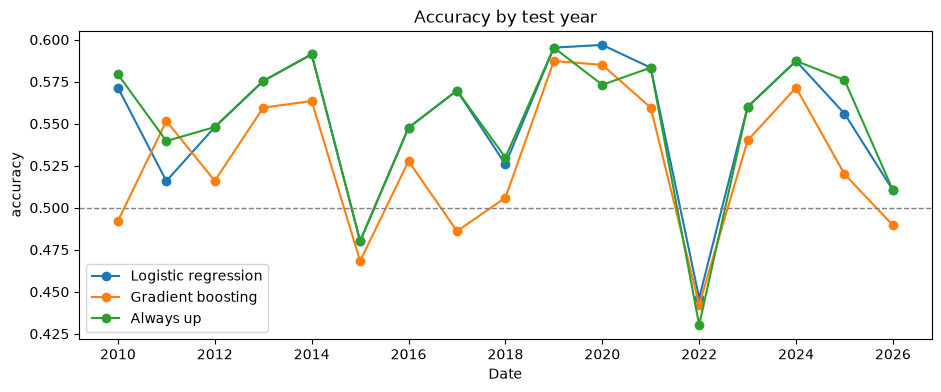

In [9]:
by_year = accuracy_by_year(all_preds, test["target"])
ax = by_year[list(model_preds) + ["Always up"]].plot(marker="o", title="Accuracy by test year")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("accuracy")
plt.show()

Questions to ask yourself here: does a model beat "always up" consistently, or only in a few years? Which years are bad, and what happened in markets then?

### Do the three left-out features help?

The same walk-forward test with all eight features. If the left-out features only repeated what the kept ones already say, accuracy should barely change.

In [10]:
rows = {}
for name, model in get_models().items():
    for label, feats in [("5 features", FEATURES), ("all 8 features", ALL_FEATURES)]:
        p = walk_forward(model, data, FIRST_TEST_YEAR, features=feats)
        rows[(name, label)] = {"accuracy": (p["pred"] == test["target"]).mean(),
                               "predicted up": p["pred"].mean()}
pd.DataFrame(rows).T

accuracy  predicted up
Logistic regression 5 features        0.5512        0.9848
                    all 8 features    0.5508        0.9758
Gradient boosting   5 features        0.5280        0.7827
                    all 8 features    0.5268        0.7697

## 5. Backtest: would it have made money?

Strategy: at each close, hold the stock into tomorrow if the model predicts up, otherwise sit in cash. Each buy or sell costs `COST`. Compared against buying once and holding.

In [11]:
positions = {"Buy and hold": pd.Series(1, index=test.index)}
positions.update({name: p["pred"] for name, p in model_preds.items()})

stats, daily_returns = backtest_table(positions, test["next_ret"], cost=COST)
stats

,total return,annual return,annual volatility,Sharpe ratio,max drawdown,days in market,trades
Buy and hold,8.1640,0.1416,0.1704,0.8627,-0.3372,1.0000,1
Logistic regression,9.2211,0.1491,0.1648,0.9257,-0.2667,0.9848,97
Gradient boosting,1.4062,0.0539,0.1473,0.4299,-0.2738,0.7827,1110


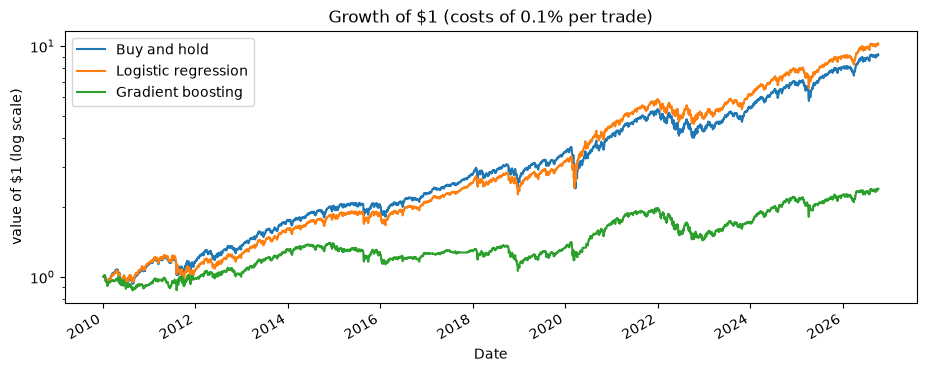

In [12]:
ax = (1 + daily_returns).cumprod().plot(logy=True, title=f"Growth of $1 (costs of {COST:.1%} per trade)")
ax.set_ylabel("value of $1 (log scale)")
plt.show()

Trading costs matter. Here's the same backtest at different cost levels. A strategy that only wins when trading is free isn't a real edge.

In [13]:
rows = {}
for cost in [0, 0.0005, 0.001, 0.002]:
    s, _ = backtest_table(positions, test["next_ret"], cost=cost)
    rows[f"{cost:.2%}"] = s["annual return"]
pd.DataFrame(rows).rename_axis(columns="cost per trade")

cost per trade,0.00%,0.05%,0.10%,0.20%
Buy and hold,0.1416,0.1416,0.1416,0.1415
Logistic regression,0.1557,0.1524,0.1491,0.1424
Gradient boosting,0.1262,0.0894,0.0539,-0.0138


### Is any edge just luck?

A strategy that sits in cash on a few days can beat buy-and-hold just by happening to miss some bad days. To check, keep the same number of cash days but pick them at random, 2,000 times. The random versions trade for free, which is generous to luck, so this is a strict test.

- **share of random >=**: how often a random choice of cash days did at least as well. Around 0.05 or less is hard to explain by luck; much higher means the result is easy to get by chance.
- **Biggest days avoided / missed**: if a handful of extreme days drive the result, it's fragile. One lucky day in a crash can make a strategy look good for a decade.

In [14]:
from src.evaluate import luck_check

luck = {}
for name, p in model_preds.items():
    if p["pred"].mean() < 1:
        luck[name] = luck_check(p["pred"], test["next_ret"], cost=COST)
display(pd.DataFrame(luck).T)

for name, p in model_preds.items():
    cash_days = test.loc[p["pred"] == 0, "next_ret"].sort_values()
    if len(cash_days) == 0:
        continue
    print(f"\n{name}: {len(cash_days)} days in cash")
    print("  Biggest drops avoided:", ", ".join(f"{d.date()} {r:+.1%}" for d, r in cash_days.head(3).items()))
    print("  Biggest rises missed: ", ", ".join(f"{d.date()} {r:+.1%}" for d, r in cash_days.tail(3)[::-1].items()))

,annual return,random median,share of random >=,cash days
Logistic regression,0.1491,0.1392,0.0475,64.0000
Gradient boosting,0.0539,0.1086,0.9985,916.0000



Logistic regression: 64 days in cash
  Biggest drops avoided: 2020-03-13 -10.9%, 2020-03-17 -5.1%, 2011-08-09 -4.4%
  Biggest rises missed:  2020-04-07 +3.4%, 2011-08-22 +3.3%, 2011-11-25 +2.9%

Gradient boosting: 916 days in cash
  Biggest drops avoided: 2020-03-13 -10.9%, 2020-03-11 -9.6%, 2020-06-10 -5.8%
  Biggest rises missed:  2020-03-23 +9.1%, 2020-04-03 +6.7%, 2020-03-25 +5.8%


## 6. Checking the pipeline itself

Two tests on fake prices, run through exactly the same code as the real data. Together they show the "detector" works both ways.

### 6a. Pure noise: the models should find nothing

Fake prices where every day is pure chance. Nothing can be predicted, so the models should land close to "always up." If a model clearly beats it here, the code is leaking future information and the real results can't be trusted.

In [15]:
def check_on_fake_prices(fake_prices):
    fake = build_dataset(fake_prices)
    start_year = first_test_year(fake)
    fake_test = fake[fake.index.year >= start_year]
    preds = {name: walk_forward(m, fake, start_year)["pred"] for name, m in get_models().items()}
    preds["Always up"] = pd.Series(1, index=fake_test.index)
    preds["Repeat last move"] = (fake_test["ret_1d"] > 0).astype(int)
    return accuracy_table(preds, fake_test["target"])

check_on_fake_prices(make_random_walk(n_days=len(prices), start=prices.index[0]))

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.4889,0.4737,0.5040,0.3704,0.9272,False
Gradient boosting,0.4881,0.4730,0.5033,0.4761,0.9392,False
Always up,0.5028,0.4876,0.5179,1.0000,0.3667,False
Repeat last move,0.4965,0.4813,0.5117,0.5028,0.6789,False


### 6b. A planted pattern: the models should find it

Fake prices with a pattern built in on purpose: after an up day, the next day is down 60% of the time, and after a down day, the next day is up 60% of the time. Up and down days are equally common, so "always up" scores about 50%, while a model that learns "bet against yesterday's move" should score about 60%. Both models should show **True** in "beats always-up?".

This is what makes the real-data result meaningful: the same code finds a pattern when one exists, so finding nothing in real prices means there was nothing to find.

In [16]:
check_on_fake_prices(make_planted_pattern(n_days=len(prices), start=prices.index[0]))

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.5927,0.5778,0.6076,0.5020,0.0000,True
Gradient boosting,0.5812,0.5662,0.5961,0.5188,0.0000,True
Always up,0.4956,0.4804,0.5107,1.0000,0.7219,False
Repeat last move,0.3953,0.3805,0.4102,0.4956,1.0000,False


## 7. What did logistic regression learn?

Weights from a model fitted on all the data. Features were scaled first, so the sizes are comparable: positive means "this pushes toward predicting up." With five non-overlapping features, each bar can be read on its own. This describes the model; it doesn't prove the patterns are real.

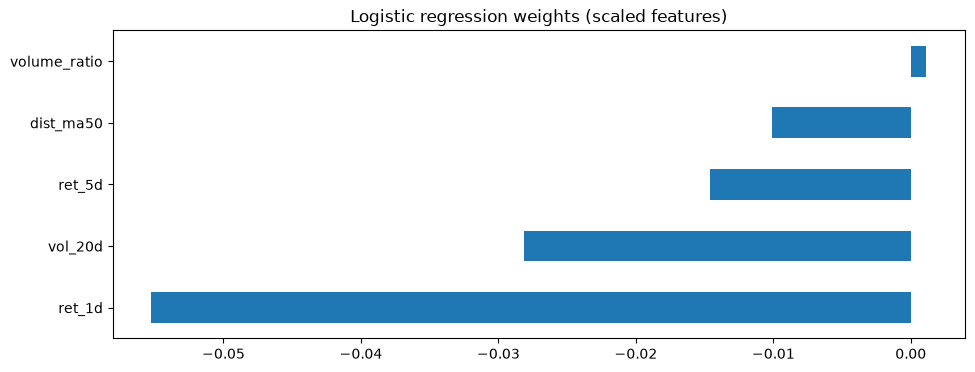

In [17]:
logreg = get_models()["Logistic regression"].fit(data[FEATURES], data["target"])
weights = pd.Series(logreg[-1].coef_[0], index=FEATURES).sort_values()
weights.plot.barh(title="Logistic regression weights (scaled features)")
plt.show()

## 8. Conclusions

*Write this after running the notebook, in your own words. It's the most important part for a portfolio reader.* Some prompts:

- Did either model beat "always up" beyond the noise range? By how much?
- Was any edge consistent across years, or concentrated in a few?
- Did the backtest beat buy-and-hold after costs? On return, on Sharpe ratio, on drawdown?
- What did the two pipeline checks show, and why do they matter?
- Why do you think daily direction is so hard to predict?

## Ideas to try next

- Other tickers (single stocks, other markets, `^VIX`-based features)
- Trade only when the model is confident, e.g. `prob_up > 0.55`
- Predict weekly instead of daily direction
- An LSTM, judged against the same baselines and the same walk-forward test